# Figure 8-5 — sensitivity

Normalized sensitivity is (x / m) (∂m / ∂x) from a central difference on the
passives. The cutoff frequency depends on R2, R3, C1, and C2. R1 does not
enter ω0. It does enter Q, so it still moves the −3 dB frequency a little.

The DC table uses Vin = 1 V so the gain −R3/R1 is visible. At the 0 V
study bias, and with bias current equal to zero, every passive has a zero
DC output. Vos enters as V(n2) = −Vos, so its DC gain is −(1 + R3/R1).
Ibp does not enter the signal nodes. Ibn leaves the inverting node.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


In [3]:
from mfb_design.sensitivity import dc_vout_influence, full_sensitivity, sensitivity_vs_frequency

sens = full_sensitivity(p)
fc = sens.normalized[sens.normalized["metric"] == "fc_hz"].copy()
display(fc[["parameter", "normalized_sensitivity", "nominal_metric"]])
tone = sens.normalized[sens.normalized["metric"] == "gain_at_passband"][
    ["parameter", "normalized_sensitivity"]
]
display(tone)


parameter,normalized_sensitivity,nominal_metric
R1,0.413774,495373
R2,-0.822176,495373
R3,-0.591597,495373
C1,0.00537116,495373
C2,-1.00537,495373


parameter,normalized_sensitivity
R1,-0.804927
R2,-0.213824
R3,0.894882
C1,0.176321
C2,-0.30019


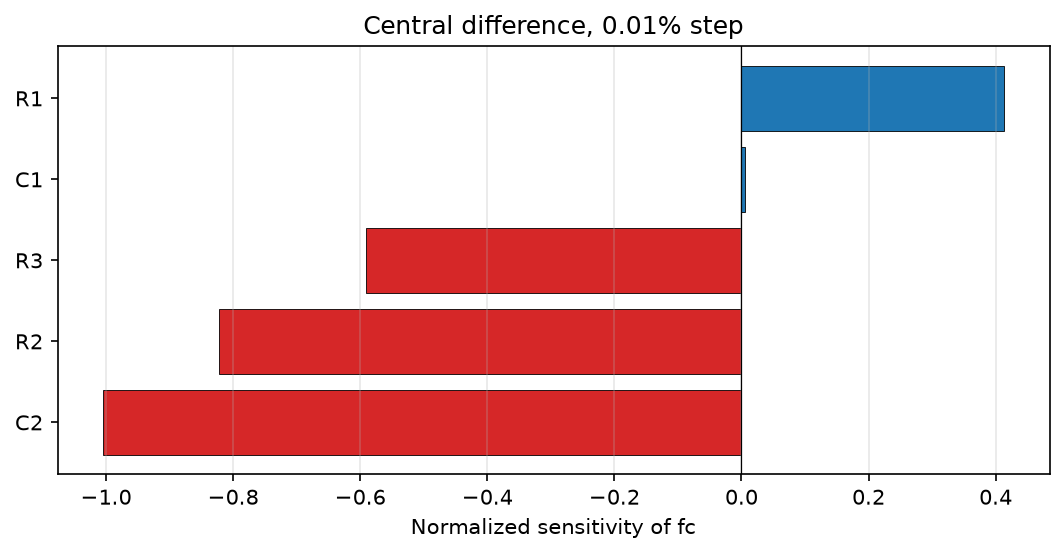

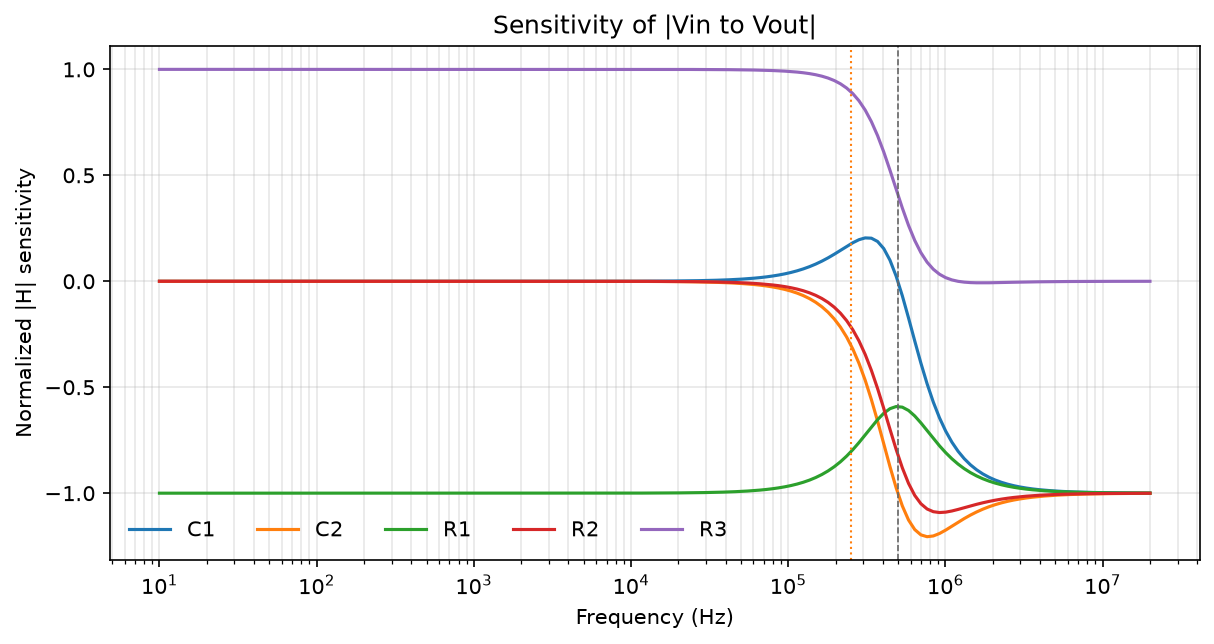

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
order = fc.sort_values("normalized_sensitivity")
colors = ["C3" if v < 0 else "C0" for v in order["normalized_sensitivity"]]
ax.barh(order["parameter"], order["normalized_sensitivity"], color=colors, edgecolor="k", linewidth=0.4)
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("Normalized sensitivity of fc")
ax.set_title("Central difference, 0.01% step")
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "07_fc_sensitivity.png", dpi=150)
plt.show()

svf = sensitivity_vs_frequency(p)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
for name, g in svf.groupby("parameter"):
    ax.semilogx(g["f_hz"], g["S_mag"], lw=1.5, label=name)
ax.axvline(p.op.f_design_hz, color="0.4", ls="--", lw=0.8)
ax.axvline(p.op.f_passband_hz, color="C1", ls=":", lw=1.0)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Normalized |H| sensitivity")
ax.set_title("Sensitivity of |Vin to Vout|")
ax.grid(True, which="both", alpha=0.3)
ax.legend(frameon=False, ncol=5)
fig.tight_layout()
fig.savefig(FIG / "07_sensitivity_vs_frequency.png", dpi=150)
plt.show()


## DC output at Vin = 1 V

R1 and R3 set the DC gain, so their ±0.1% boxes move Vout by about a
millivolt at this input. Vos at ±200 µV moves Vout by −2·Vos, an 800 µV
span. Ibn at ±10 pA is tens of nanovolts. Ibp is zero in this topology.


Vos span is -800.0 µV.
Ibn span is 60.58 nV.
Ibp span is 0.000e+00 µV.


parameter,Vout_nominal_V,Vout_at_lo_V,Vout_at_hi_V,span_uV,note
R1,-1,-1.001,-0.999001,2000,Ib = 0. DC gain depends on R3/R1 only.
R2,-1,-1,-1,0,Ib = 0. DC gain depends on R3/R1 only.
R3,-1,-0.999,-1.001,-2000,Ib = 0. DC gain depends on R3/R1 only.
C1,-1,-1,-1,0,Ib = 0. DC gain depends on R3/R1 only.
C2,-1,-1,-1,0,Ib = 0. DC gain depends on R3/R1 only.
R1 at Ibn = Ib max,-1,-1.001,-0.999001,2000,Ibn = +10 pA. The span is the tolerance piece of that drop.
R2 at Ibn = Ib max,-1,-1,-1,4.96e-05,Ibn = +10 pA. The span is the tolerance piece of that drop.
R3 at Ibn = Ib max,-1,-0.999,-1.001,-2000,Ibn = +10 pA. The span is the tolerance piece of that drop.
Vos,-1,-0.9996,-1.0004,-800,"V(n2) = −Vos, so Vout moves by −(1 + R3/R1) Vos."
Ibp,-1,-1,-1,0,+ pin is grounded. Ibp does not enter the signal nodes.


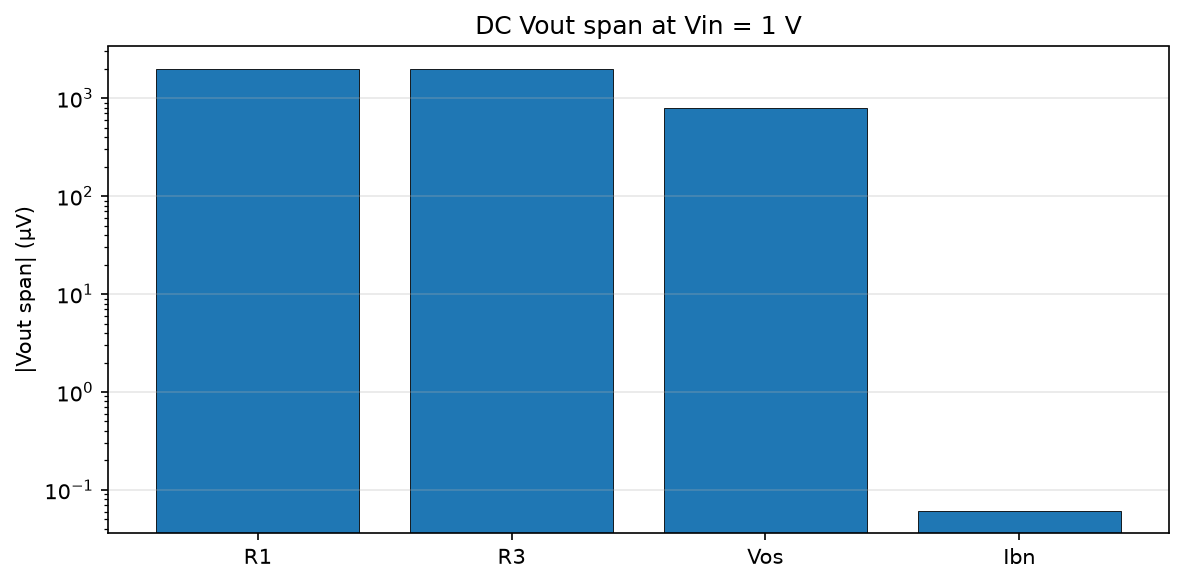

In [5]:
inf = dc_vout_influence(p, vin=1.0)
display(inf)
vos = inf.loc[inf["parameter"] == "Vos"].iloc[0]
ibn = inf.loc[inf["parameter"] == "Ibn"].iloc[0]
ibp = inf.loc[inf["parameter"] == "Ibp"].iloc[0]
print(f"Vos span is {vos['span_uV']:.1f} µV.")
print(f"Ibn span is {ibn['span_uV']*1e3:.2f} nV.")
print(f"Ibp span is {ibp['span_uV']:.3e} µV.")

main = inf[inf["parameter"].isin(["R1", "R2", "R3", "C1", "C2", "Vos", "Ibp", "Ibn"])].copy()
main = main[main["span_uV"].abs() > 1e-6]
fig, ax = plt.subplots(figsize=(8.0, 4.0))
span = main["span_uV"].abs()
ax.bar(main["parameter"], span, color="C0", edgecolor="k", linewidth=0.4)
ax.set_ylabel("|Vout span| (µV)")
ax.set_yscale("log")
ax.set_title("DC Vout span at Vin = 1 V")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "07_dc_vout_span.png", dpi=150)
plt.show()
